<table width="100%" style="border:none; border-collapse:collapse;">
<tr style="border:none;">
<td width="150" style="border:none;"></td>
<td align="center" style="border:none;">
    <h1>Tarea Semanal 9</h1>
    <h2>Teoria de los Circuitos II - R4052</h2>
    <h3>Fabian Alexander Iturrizaga Meza</h3>
    <br>
    <b>Docentes</b><br>
    Profesor: Mariano Llamedo Soria<br>
    Jefe de TPs: Cesar Fuoco<br>
    Ayudante de TPs: David Moharos
</td>
<td width="150" align="right" style="border:none; vertical-align:top;"><img src="./img/logo_UTN.svg" width="150" /></td>
</tr>
</table>

***

## Informe de la tarea semanal

## Consigna

<div align="center"><img src="./img/consigna_1.png" alt="Consigna puntos 1 y 2" width="700"/></div>

<div align="center"><img src="./img/consigna_2.png" alt="Consigna punto 3" width="700"/></div>

<div align="center"><img src="./img/consigna_3.png" alt="Indicaciones generales" width="700"/></div>

## Herramientas de verificación simbólica

Se modelan los cuadripolos como redes π. Se obtienen los parámetros Z con funciones de pytc2.cuadripolos y luego se incorporan las conexiones de fuente y carga.

In [1]:
import sympy as sp
from pytc2.cuadripolos import calc_MAI_impedance_ij, calc_MAI_ztransf_ij_mn
from pytc2.remociones import remover_polo_dc, remover_polo_infinito, remover_polo_jw, isFRP
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s, s
from schemdraw import Drawing
from pytc2.dibujar import (dibujar_puerto_entrada, dibujar_puerto_salida,
                          dibujar_elemento_serie, dibujar_elemento_derivacion,
                          dibujar_tanque_serie, dibujar_espacio_derivacion)

def mostrar_funcion(nombre, expresion):
    """Muestra la función con los polinomios mónicos y el factor común fuera."""
    expr = sp.cancel(expresion)
    numerador, denominador = sp.fraction(expr)
    pol_num = sp.Poly(numerador, s)
    pol_den = sp.Poly(denominador, s)
    factor = sp.factor(pol_num.LC() / pol_den.LC())
    num_monic = pol_num.monic().as_expr()
    den_monic = pol_den.monic().as_expr()

    if pol_num.degree() == 0 and pol_den.degree() == 0:
        rhs = sp.latex(expr)
    else:
        factor_latex = "" if factor == 1 else sp.latex(factor) + r"\,"
        if den_monic == 1:
            rhs = factor_latex + sp.latex(num_monic)
        elif num_monic == 1:
            rhs = factor_latex + r"\frac{1}{" + sp.latex(den_monic) + "}"
        else:
            rhs = factor_latex + r"\frac{" + sp.latex(num_monic) + "}{" + sp.latex(den_monic) + "}"
    print_latex(nombre + "=" + rhs)

def mostrar_componente(nombre, valor, unidad):
    print_latex(a_equal_b_latex_s(nombre, sp.simplify(valor)))
    print(f"Unidad: {unidad}")

def matriz_mai_pi(Y1, Ym, Y2):
    """MAI de red pi con admitancias de puerto y rama entre puertos."""
    return sp.Matrix([[Y1 + Ym, -Ym, -Y1],
                      [-Ym, Y2 + Ym, -Y2],
                      [-Y1, -Y2, Y1 + Y2]])

def parametros_z_pytc2(Ymai):
    Z11 = sp.factor(calc_MAI_impedance_ij(Ymai, 0, 2))
    Z22 = sp.factor(calc_MAI_impedance_ij(Ymai, 1, 2))
    Z21 = sp.factor(calc_MAI_ztransf_ij_mn(Ymai, 1, 2, 2, 0))
    return Z11, Z21, Z22

## Punto 1

### Resolución manuscrita

<div align="center"><img src="./img/ejercicio1_1.jpg" alt="Punto 1, resolución manuscrita, hoja 1" width="700"/></div>

<div align="center"><img src="./img/ejercicio1_2.jpg" alt="Punto 1, resolución manuscrita, hoja 2" width="700"/></div>

<div align="center"><img src="./img/ejercicio1_3.jpg" alt="Punto 1, resolución manuscrita, hoja 3" width="700"/></div>

<div align="center"><img src="./img/ejercicio1_4.jpg" alt="Punto 1, resolución manuscrita, hoja 4" width="700"/></div>

<div align="center"><img src="./img/ejercicio1_5.jpg" alt="Punto 1, resolución manuscrita, hoja 5" width="700"/></div>

### Simulación en LTspice

#### Circuito del cuadripolo

<div align="center"><img src="./img/punto1_circuito_cuadripolos.png" alt="Cuadripolo punto 1" width="850"/></div>

**Correspondencia:** circuito de medición simultánea de $Z_{11}=V_1/I_1$ y $Z_{21}=V_2/I_1$. El puerto 2 está abierto ($I_2=0$) y se excita el puerto 1.

#### Transferencia completa

<div align="center"><img src="./img/punto1_circuito_transferencia.png" alt="Circuito de transferencia punto 1" width="850"/></div>

**Correspondencia:** circuito para medir la transferencia de tensión $V_2/V_g$, con $R_g=1\,\Omega$ en serie y el puerto 2 abierto.

#### Transferencias con cursores

<div align="center"><img src="./img/punto1_trasnferencia_1.png" alt="Transferencia punto 1, cursor 1" width="100%"/></div>

**Respuesta, polos y ceros:** la respuesta es pasaaltos con un cero en continua y una muesca de transmisión en $s=\pm j0.25\,\mathrm{rad/s}$, que corresponde a $f_0=0.25/(2\pi)=39.7887\,\mathrm{mHz}$. El cursor marca $39.810717\,\mathrm{mHz}$ y $-95.251009\,\mathrm{dB}$: está muy cerca del cero ideal, pero no exactamente en él porque el barrido AC toma puntos discretos. Los polos son $s=-1$ y $s=(-1\pm j\sqrt{3})/2\,\mathrm{rad/s}$. En la banda pasante alta, $|V_2/V_g|\to1$ ($0\,\mathrm{dB}$), como muestra la lectura a $100\,\mathrm{Hz}$ en la siguiente captura.
<div align="center"><img src="./img/punto1_trasnferencia_2.png" alt="Transferencia punto 1, cursor 2" width="100%"/></div>

**Respuesta, polos y ceros:** es la misma pasaaltos con cero en $s=0$ y cero de transmisión en $s=\pm j0.25\,\mathrm{rad/s}$ ($39.7887\,\mathrm{mHz}$). Sus polos están en $s=-1$ y $s=(-1\pm j\sqrt{3})/2\,\mathrm{rad/s}$. El cursor está a **100 Hz** y mide $-1.3751011\,\mathrm{mdB}=-0.0013751\,\mathrm{dB}$, prácticamente el nivel de banda pasante previsto: $|V_2/V_g|\to1$ ($0\,\mathrm{dB}$).

#### Parámetros Z con cursores

<div align="center"><img src="./img/punto1_parametro_z11.png" alt="Parámetro Z11 punto 1" width="100%"/></div>

**Polos y ceros de $Z_{11}$:** polos en $s=\pm j/\sqrt{2}=\pm j0.7071\,\mathrm{rad/s}$ ($112.54\,\mathrm{mHz}$); ceros en $s=0$ y $s=\pm j\sqrt{2}=\pm j1.4142\,\mathrm{rad/s}$ ($225.08\,\mathrm{mHz}$ para el par).
<div align="center"><img src="./img/punto1_parametro_z21.png" alt="Parámetro Z21 punto 1" width="100%"/></div>

**Polos y ceros de $Z_{21}$:** polos en $s=\pm j/\sqrt{2}=\pm j0.7071\,\mathrm{rad/s}$ ($112.54\,\mathrm{mHz}$); ceros en $s=0$ y $s=\pm j0.25\,\mathrm{rad/s}$ ($39.79\,\mathrm{mHz}$ para el par).

### Verificación simbólica con pytc2

Con salida abierta y Rg=1 ohm, V2/Vg=Z21/(Z11+Rg).

In [2]:
L1_1, L2_1, L3_1 = sp.Rational(31,14), sp.Rational(961,48), sp.Rational(31,48)
C_1 = sp.Rational(768,961)
Ymai_1 = matriz_mai_pi(1/(s*L1_1), 1/(s*L2_1)+s*C_1, 1/(s*L3_1))
Z11_1, Z21_1, Z22_1 = parametros_z_pytc2(Ymai_1)

print_subtitle("Punto 1: parámetros Z del cuadripolo")
mostrar_funcion("Z_{11}(s)", Z11_1)
mostrar_funcion("Z_{21}(s)", Z21_1)


#### Punto 1: parámetros Z del cuadripolo

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Esquema del cuadripolo sintetizado

La figura muestra la red π de dos puertos con los valores obtenidos en la síntesis. Las fuentes y terminaciones externas se muestran en los circuitos de medición de LTspice.

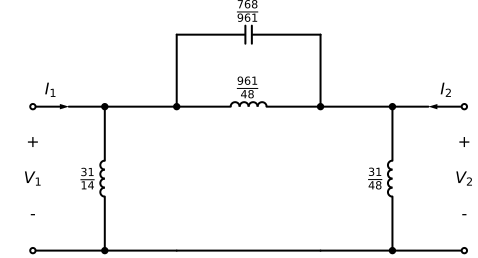

In [3]:
d1 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
d1 = dibujar_elemento_derivacion(d1, 'L', L1_1)
d1 = dibujar_espacio_derivacion(d1)
d1 = dibujar_tanque_serie(d1, L2_1, C_1)
d1 = dibujar_espacio_derivacion(d1)
d1 = dibujar_elemento_derivacion(d1, 'L', L3_1)
d1 = dibujar_puerto_salida(
    d1,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2$',
)
display(d1)

#### Circuito de transferencia con excitación $V_g$

Este esquema muestra la fuente ideal $V_g$ en serie con $R_g=1\,\Omega$, como en LTspice. El puerto 2 permanece abierto ($I_2=0$).

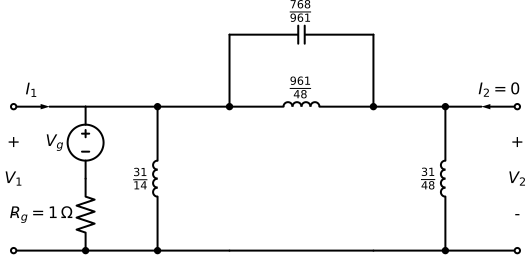

In [4]:
from schemdraw import elements as elm

dc1 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
# Rama de fuente Thevenin: Vg en serie con Rg entre el puerto de entrada y retorno.
dc1.push()
dc1 += elm.SourceV().down().reverse().length(dc1.unit * 0.5).label(r'$V_g$', fontsize=16)
dc1 += elm.ResistorIEEE().down().length(dc1.unit * 0.5).label(r'$R_g=1\,\Omega$', fontsize=16)
dc1 += elm.Dot()
dc1.pop()
dc1 = dibujar_espacio_derivacion(dc1)
dc1 = dibujar_elemento_derivacion(dc1, 'L', L1_1)
dc1 = dibujar_espacio_derivacion(dc1)
dc1 = dibujar_tanque_serie(dc1, L2_1, C_1)
dc1 = dibujar_espacio_derivacion(dc1)
dc1 = dibujar_elemento_derivacion(dc1, 'L', L3_1)
dc1 = dibujar_puerto_salida(
    dc1,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2=0$',
)
display(dc1)

#### Remoción parcial en continua de la admitancia vista desde el puerto 1

Se usa la admitancia de entrada $Y_{\mathrm{in},1}^{(I_2=0)}=\left.I_1/V_1\right|_{I_2=0}=1/Z_{11}$. El puerto 2 está abierto. Esta admitancia de entrada no es el parámetro matricial $Y_{11}$, que se define con $V_2=0$. Se remueve parcialmente el polo en $s=0$ para ubicar un cero del remanente en $\omega=1/4\,\mathrm{rad/s}$; la rama extraída es $L_1$.

In [5]:
Yin1_I2zero_s1 = sp.factor(1 / Z11_1)
Y2_s1, YL1_s1 = remover_polo_dc(Yin1_I2zero_s1, omega_zero=0.25)
Y2_s1 = sp.factor(sp.nsimplify(Y2_s1))
YL1_s1 = sp.factor(sp.nsimplify(YL1_s1))
L1_s1 = sp.simplify(1 / (s * YL1_s1))

print_subtitle("Remoción parcial en continua: extracción de L1")
mostrar_funcion(r"Y_{\mathrm{in},1}^{(I_2=0)}(s)", Yin1_I2zero_s1)
mostrar_funcion("Y_{L_1}(s)", YL1_s1)
mostrar_componente("L_1", L1_s1, "H")
mostrar_funcion("Y_2(s)", Y2_s1)
print("Y2 es FRP:", isFRP(Y2_s1))

assert sp.simplify(L1_s1 - L1_1) == 0
assert sp.simplify(Y2_s1.subs(s, sp.I/4)) == 0

#### Remoción parcial en continua: extracción de L1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


<IPython.core.display.Math object>

Y2 es FRP: True


#### Remoción del polo finito en ω=1/4 rad/s

Se invierte la admitancia remanente y se remueve el par de polos imaginarios de Z2 con remover_polo_jw. El remanente final es la impedancia inductiva asociada a L3.

In [6]:
Z2_s1 = sp.factor(1 / Y2_s1)
Z4_s1, ZLC_s1, L2_s1, C1_s1 = remover_polo_jw(
    Z2_s1, omega=0.25, isImpedance=True
)
Z4_s1 = sp.factor(sp.nsimplify(Z4_s1, tolerance=1e-10))
ZLC_s1 = sp.factor(sp.nsimplify(ZLC_s1, tolerance=1e-10))
L2_s1 = sp.nsimplify(L2_s1, tolerance=1e-10)
C1_s1 = sp.nsimplify(C1_s1, tolerance=1e-10)
L3_s1 = sp.simplify(sp.limit(Z4_s1 / s, s, sp.oo))

Z11_recon_s1 = sp.factor(1 / (YL1_s1 + 1 / (ZLC_s1 + Z4_s1)))
print_subtitle("Remoción del polo finito en omega = 1/4 rad/s")
mostrar_funcion("Z_2(s)", Z2_s1)
mostrar_funcion("Z_{L_2C_1}(s)", ZLC_s1)
mostrar_componente("L_2", L2_s1, "H")
mostrar_componente("C_1", C1_s1, "F")
mostrar_funcion("Z_4(s)", Z4_s1)
mostrar_componente("L_3", L3_s1, "H")
mostrar_funcion("Z_{11, reconstruida}(s)", Z11_recon_s1)
print("Z4 es FRP:", isFRP(Z4_s1))

assert L2_s1 == L2_1 and C1_s1 == C_1 and L3_s1 == L3_1
assert sp.simplify(Z11_recon_s1 - Z11_1) == 0

#### Remoción del polo finito en omega = 1/4 rad/s

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


<IPython.core.display.Math object>

Z4 es FRP: True


In [7]:
T1 = sp.factor(Z21_1/(Z11_1+1))
T1_objetivo = s*(s**2+sp.Rational(1,16))/(s**3+2*s**2+2*s+1)
k1 = sp.simplify(T1/T1_objetivo)

print_subtitle("Punto 1: transferencia cargada")
mostrar_funcion("T_1(s)=V_2/V_g", T1)
mostrar_funcion("T_{objetivo}(s)", T1_objetivo)
mostrar_componente("k_1", k1, "adimensional")

assert sp.simplify(T1-T1_objetivo)==0
assert k1==1

#### Punto 1: transferencia cargada

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: adimensional


La identidad simbólica confirma la transferencia para k=1.

## Punto 2

### Resolución manuscrita

**Aclaración sobre la resolución manual.** En el esquema final de la hoja 3 invertí la orientación de la red: al sintetizar $Z_{22}=V_2/I_2$, la primera remoción, $C_1=7/17\,\mathrm{F}$, debe ubicarse en el puerto 2, del lado de la carga $R_L$. En mi dibujo quedó del lado del generador, como si la síntesis partiera de $Z_{11}$. Los cálculos y valores de los componentes no cambian; el error está en la ubicación de $C_1$ y $C_3$ en ese dibujo. Los apartados posteriores de LTspice y verificación simbólica muestran el orden correcto: $C_3$ junto al puerto 1 y $C_1$ junto al puerto 2.

En la última hoja calculo $Z_{12,\mathrm{red}}$. Es válido compararlo con el $Z_{21}$ solicitado porque esta red LC es recíproca y $Z_{12}=Z_{21}$. La reciprocidad explica que el parámetro cruzado coincida al mirar la red desde el puerto opuesto; el factor $k=1/9$ sale del coeficiente de la función obtenida al compararla con la función objetivo, no de la reciprocidad por sí sola. Además, invertir la red intercambia $Z_{11}$ y $Z_{22}$ pero deja iguales $Z_{12}$ y $Z_{21}$; por eso esa verificación da bien aunque el dibujo manual haya invertido $C_1$ y $C_3$. Para la transferencia cargada, sí importa la orientación: $C_1$ debe quedar en el puerto 2 junto a $R_L$ y $C_3$ en el puerto 1 junto al generador.

<div align="center"><img src="./img/ejercicio2_1.jpg" alt="Punto 2, resolución manuscrita, hoja 1" width="700"/></div>

<div align="center"><img src="./img/ejercicio2_2.jpg" alt="Punto 2, resolución manuscrita, hoja 2" width="700"/></div>

<div align="center"><img src="./img/ejercicio2_3.jpg" alt="Punto 2, resolución manuscrita, hoja 3" width="700"/></div>

<div align="center"><img src="./img/ejercicio2_4.jpg" alt="Punto 2, resolución manuscrita, hoja 4" width="700"/></div>

### Simulación en LTspice

**Aclaración:** A partir de este inciso, los circuitos están dibujados con la orientación correcta: $C_3=27/17\,\mathrm{F}$ queda en el puerto 1, junto al generador, y $C_1=7/17\,\mathrm{F}$ en el puerto 2, junto a la carga. Las mediciones de $Z_{21}$, $Z_{22}$ y la transferencia usan esta asignación.

#### Circuitos

<div align="center"><img src="./img/punto2_circuito_cuadripolos_z21.png" alt="Medición de Z21 punto 2" width="850"/></div>

**Correspondencia:** circuito de medición de $Z_{21}=V_2/I_1$, con excitación de corriente en el puerto 1 y puerto 2 abierto ($I_2=0$). En esta misma configuración también puede obtenerse $Z_{11}=V_1/I_1$.
<div align="center"><img src="./img/punto2_circuito_cuadripolos_z22.png" alt="Medición de Z22 punto 2" width="850"/></div>

**Correspondencia:** circuito de medición de $Z_{22}=V_2/I_2$, con excitación en el puerto 2 y puerto 1 abierto ($I_1=0$). También se obtiene $Z_{12}=V_1/I_2$, que coincide con $Z_{21}$ por reciprocidad.
<div align="center"><img src="./img/punto2_circuito_transferencia.png" alt="Circuito de transferencia punto 2" width="850"/></div>

**Correspondencia:** circuito para medir la transimpedancia $V_2/I_1$ con la carga $R_L=1\,\Omega$ conectada al puerto 2.

#### Transferencia y parámetros Z con cursores

<div align="center"><img src="./img/punto2_transferencia.png" alt="Transferencia punto 2 con cursor" width="100%"/></div>

**Respuesta, polos y ceros:** la respuesta es pasabajos. Tiene ganancia de continua $V_2/I_1=1\,\Omega$ ($0\,\mathrm{dB}$) y tiende a cero en alta frecuencia. Sus polos son $s=-1$ y $s=(-1\pm j\sqrt{3})/2\,\mathrm{rad/s}$; el cero de transmisión está en $s=\pm j3\,\mathrm{rad/s}$, equivalente a $f_0=3/(2\pi)=477.4648\,\mathrm{mHz}$. El cursor marca $477.52927\,\mathrm{mHz}$ y $-100.01068\,\mathrm{dB}$, muy cerca del cero ideal; el pequeño residuo se debe al paso discreto del barrido. El cursor de baja frecuencia, a $100\,\mathrm{\mu Hz}$, mide $-0.38100576\,\mathrm{dB}$, próximo al límite de $0\,\mathrm{dB}$.
<div align="center"><img src="./img/punto2_parametro_z21.png" alt="Parámetro Z21 punto 2 con cursor" width="100%"/></div>

**Polos y ceros de $Z_{21}$:** polos en $s=0$ y $s=\pm j\sqrt{2}=\pm j1.4142\,\mathrm{rad/s}$ ($225.08\,\mathrm{mHz}$ para el par); ceros en $s=\pm j3\,\mathrm{rad/s}$ ($477.46\,\mathrm{mHz}$).
<div align="center"><img src="./img/punto2_parametro_z22.png" alt="Parámetro Z22 punto 2 con cursor" width="100%"/></div>

**Polos y ceros de $Z_{22}$:** polos en $s=0$ y $s=\pm j\sqrt{2}=\pm j1.4142\,\mathrm{rad/s}$ ($225.08\,\mathrm{mHz}$ para el par); ceros en $s=\pm j/\sqrt{2}=\pm j0.7071\,\mathrm{rad/s}$ ($112.54\,\mathrm{mHz}$).

### Verificación simbólica con pytc2

Con RL=1 ohm, I2=-V2/RL y V2/I1=Z21 RL/(RL+Z22).

In [8]:
C3_2, C2_2 = sp.Rational(27,17), sp.Rational(27,289)
L_2, C1_2 = sp.Rational(289,243), sp.Rational(7,17)
Ymai_2 = matriz_mai_pi(s*C3_2, 1/(s*L_2)+s*C2_2, s*C1_2)
Z11_2, Z21_2, Z22_2 = parametros_z_pytc2(Ymai_2)

print_subtitle("Punto 2: parámetros Z del cuadripolo")

mostrar_funcion("Z_{21}(s)", Z21_2)
mostrar_funcion("Z_{22}(s)", Z22_2)

#### Punto 2: parámetros Z del cuadripolo

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Esquema del cuadripolo sintetizado

La red π se dibuja con los capacitores de derivación y el tanque paralelo $L_2\parallel C_2$ en la rama serie entre puertos.

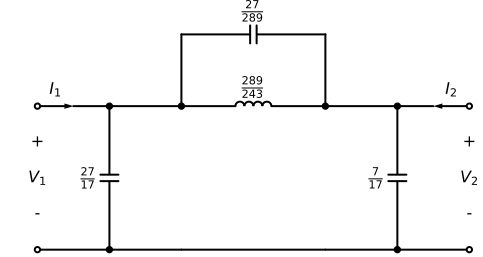

In [9]:
d2 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
d2 = dibujar_elemento_derivacion(d2, 'C', C3_2)
d2 = dibujar_espacio_derivacion(d2)
d2 = dibujar_tanque_serie(d2, L_2, C2_2)
d2 = dibujar_espacio_derivacion(d2)
d2 = dibujar_elemento_derivacion(d2, 'C', C1_2)
d2 = dibujar_puerto_salida(
    d2,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2$',
)
display(d2)

#### Circuito de transferencia con fuente y carga $R_L=1\,\Omega$

La fuente de corriente excita el puerto 1 y la resistencia de carga se conecta en paralelo con la rama de salida. Así se representa la configuración usada para $V_2/I_1$.

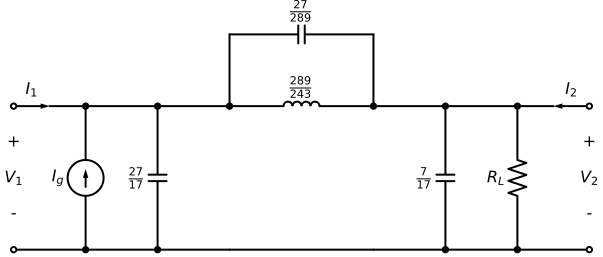

In [10]:
dc2 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
dc2 = dibujar_elemento_derivacion(dc2, 'I', r'I_g')
dc2 = dibujar_espacio_derivacion(dc2)
dc2 = dibujar_elemento_derivacion(dc2, 'C', C3_2)
dc2 = dibujar_espacio_derivacion(dc2)
dc2 = dibujar_tanque_serie(dc2, L_2, C2_2)
dc2 = dibujar_espacio_derivacion(dc2)
dc2 = dibujar_elemento_derivacion(dc2, 'C', C1_2)
dc2 = dibujar_espacio_derivacion(dc2)
dc2 = dibujar_elemento_derivacion(dc2, 'R', r'R_L')
dc2 = dibujar_puerto_salida(
    dc2,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2$',
)
display(dc2)

#### Remoción parcial en infinito de la admitancia vista desde el puerto 2

Para seguir la resolución manual, la síntesis comienza desde el puerto 2 con el puerto 1 abierto. Se usa la admitancia de entrada $Y_{\mathrm{in},2}^{(I_1=0)}=\left.I_2/V_2\right|_{I_1=0}=1/Z_{22}$. No es el parámetro matricial $Y_{22}$, que se define con $V_1=0$. La primera remoción extrae $C_1$, ubicado en el puerto 2 (lado de la carga en el circuito de transferencia).

In [11]:
Yin2_I1zero_s2 = sp.factor(1 / Z22_2)
Y2_s2, YC1_s2 = remover_polo_infinito(Yin2_I1zero_s2, omega_zero=3)
Y2_s2 = sp.factor(sp.nsimplify(Y2_s2))
YC1_s2 = sp.factor(sp.nsimplify(YC1_s2))
C1_s2 = sp.simplify(YC1_s2 / s)

print_subtitle("Remoción parcial en infinito: extracción de C1 desde el puerto 2")
mostrar_funcion(r"Y_{\mathrm{in},2}^{(I_1=0)}(s)", Yin2_I1zero_s2)
mostrar_funcion("Y_{C_1}(s)", YC1_s2)
mostrar_componente("C_1", C1_s2, "F")
mostrar_funcion("Y_2(s)", Y2_s2)
print("Y2 es FRP:", isFRP(Y2_s2))

assert C1_s2 == C1_2
assert sp.simplify(Y2_s2.subs(s, 3*sp.I)) == 0

#### Remoción parcial en infinito: extracción de C1 desde el puerto 2

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Y2 es FRP: True


#### Remoción del polo finito en $\omega=3\,\mathrm{rad/s}$

Se invierte $Y_2$ y se extrae el tanque paralelo $L_1\parallel C_2$ de la rama serie. El remanente $Z_4$ corresponde al capacitor $C_3$ del puerto 1; al volver a orientar la red para el circuito de transferencia, $C_3$ queda junto al generador.

In [12]:
Z2_s2 = sp.factor(1 / Y2_s2)
Z4_s2, ZLC_s2, L1_s2, C2_s2 = remover_polo_jw(
    Z2_s2, omega=3, isImpedance=True
)
Z4_s2 = sp.factor(sp.nsimplify(Z4_s2, tolerance=1e-10))
ZLC_s2 = sp.factor(sp.nsimplify(ZLC_s2, tolerance=1e-10))
L1_s2 = sp.nsimplify(L1_s2, tolerance=1e-10)
C2_s2 = sp.nsimplify(C2_s2, tolerance=1e-10)
C3_s2 = sp.simplify(1 / (s * Z4_s2))
Z22_recon_s2 = sp.factor(1 / (YC1_s2 + 1 / (ZLC_s2 + Z4_s2)))

print_subtitle("Remoción del polo finito en omega = 3 rad/s")
mostrar_funcion("Z_2(s)", Z2_s2)
mostrar_funcion("Z_{L_1C_2}(s)", ZLC_s2)
mostrar_componente("L_1", L1_s2, "H")
mostrar_componente("C_2", C2_s2, "F")
mostrar_funcion("Z_4(s)", Z4_s2)
mostrar_componente("C_3", C3_s2, "F")
mostrar_funcion("Z_{22, reconstruida}(s)", Z22_recon_s2)
print("Z4 es FRP:", isFRP(Z4_s2))

assert L1_s2 == L_2 and C2_s2 == C2_2 and C3_s2 == C3_2
assert sp.simplify(Z22_recon_s2 - Z22_2) == 0

#### Remoción del polo finito en omega = 3 rad/s

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: F


<IPython.core.display.Math object>

Z4 es FRP: True


In [13]:
T2 = sp.factor(Z21_2/(1+Z22_2))
T2_objetivo = (s**2+9)/(s**3+2*s**2+2*s+1)
k2 = sp.simplify(T2/T2_objetivo)

print_subtitle("Punto 2: transimpedancia con carga")
mostrar_funcion("T_2(s)=V_2/I_1", T2)
mostrar_funcion("T_{objetivo}(s)", T2_objetivo)
mostrar_componente("k_2", k2, "adimensional")

assert sp.simplify(T2-sp.Rational(1,9)*T2_objetivo)==0
assert k2==sp.Rational(1,9)

#### Punto 2: transimpedancia con carga

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: adimensional


La transferencia coincide con la expresión objetivo para k=1/9.

## Punto 3

### Resolución manuscrita

<div align="center"><img src="./img/ejercicio3_1.jpg" alt="Punto 3, resolución manuscrita, hoja 1" width="700"/></div>

<div align="center"><img src="./img/ejercicio3_2.jpg" alt="Punto 3, resolución manuscrita, hoja 2" width="700"/></div>

<div align="center"><img src="./img/ejercicio3_3.jpg" alt="Punto 3, resolución manuscrita, hoja 3" width="700"/></div>

<div align="center"><img src="./img/ejercicio3_4.jpg" alt="Punto 3, resolución manuscrita, hoja 4" width="700"/></div>

### Simulación en LTspice

#### Circuitos

<div align="center"><img src="./img/punto3_circuito_cuadripolos.png" alt="Cuadripolo punto 3" width="850"/></div>

**Correspondencia:** circuito de medición simultánea de $Z_{11}=V_1/I_1$ y $Z_{21}=V_2/I_1$. El puerto 2 está abierto ($I_2=0$) y se excita el puerto 1.
<div align="center"><img src="./img/punto3_circuito_transferencia.png" alt="Circuito de transferencia punto 3" width="850"/></div>

**Correspondencia:** circuito para medir la transimpedancia $V_2/I_g$ con excitación Norton, $R_g=1\,\Omega$ en paralelo con la fuente y el puerto 2 abierto.

#### Transferencia y parámetros Z con cursores

<div align="center"><img src="./img/punto3_transferencia.png" alt="Transferencia punto 3 con cursor" width="100%"/></div>

**Respuesta, polos y ceros:** es pasaaltos con cero en continua y cero de transmisión en $s=\pm j0.25\,\mathrm{rad/s}$ ($f_0=39.7887\,\mathrm{mHz}$). Los polos son $s=-1$ y $s=(-1\pm j\sqrt{3})/2\,\mathrm{rad/s}$. El cursor cercano al cero marca $39.810717\,\mathrm{mHz}$ y $-101.27161\,\mathrm{dB}$. En la banda pasante alta, $|V_2/I_g|\to1/2$, es decir, $-6.0206\,\mathrm{dB}$; el cursor a $100\,\mathrm{Hz}$ mide $-6.0206013\,\mathrm{dB}$ y confirma ese nivel.
<div align="center"><img src="./img/punto3_parametro_z11.png" alt="Parámetro Z11 punto 3 con cursor" width="100%"/></div>

**Polos y ceros de $Z_{11}$:** polos en $s=\pm j/\sqrt{2}=\pm j0.7071\,\mathrm{rad/s}$ ($112.54\,\mathrm{mHz}$); ceros en $s=0$ y $s=\pm j\sqrt{2}=\pm j1.4142\,\mathrm{rad/s}$ ($225.08\,\mathrm{mHz}$ para el par).
<div align="center"><img src="./img/punto3_parametro_z21.png" alt="Parámetro Z21 punto 3 con cursor" width="100%"/></div>

**Polos y ceros de $Z_{21}$:** polos en $s=\pm j/\sqrt{2}=\pm j0.7071\,\mathrm{rad/s}$ ($112.54\,\mathrm{mHz}$); ceros en $s=0$ y $s=\pm j0.25\,\mathrm{rad/s}$ ($39.79\,\mathrm{mHz}$ para el par).

### Verificación simbólica con pytc2

La fuente Norton está en paralelo con Rg=1 ohm y la salida abierta, así que V2/Ig=Z21/(1+Z11/Rg) antes de escalar. La bobina de salida L3 se divide en dos inductancias iguales y V2 se toma sobre L3B. Esta toma reduce Z21 a la mitad; el nivel de banda pasante queda en −6.02 dB, aproximadamente −6 dB.

In [14]:
# Red del punto 3: el puerto 2 se toma sobre L3B y L3A queda en serie.
Ymai_3 = sp.zeros(4)

def agregar_rama_mai(Ymai, i, j, Y):
    Ymai[i, i] += Y
    Ymai[j, j] += Y
    Ymai[i, j] -= Y
    Ymai[j, i] -= Y

L3A_3 = sp.Rational(31, 96)
L3B_3 = sp.Rational(31, 96)
agregar_rama_mai(Ymai_3, 0, 3, 1 / (s * L1_1))
agregar_rama_mai(Ymai_3, 0, 2, 1 / (s * L2_1) + s * C_1)
agregar_rama_mai(Ymai_3, 2, 1, 1 / (s * L3A_3))
agregar_rama_mai(Ymai_3, 1, 3, 1 / (s * L3B_3))

Z11_3 = sp.factor(calc_MAI_impedance_ij(Ymai_3, 0, 3))
Z21_3 = sp.factor(calc_MAI_ztransf_ij_mn(Ymai_3, 1, 3, 3, 0))
print_subtitle("Punto 3: parámetros Z calculados con pytc2")
mostrar_funcion("Z_{11,3}(s)", Z11_3)
mostrar_funcion("Z_{21,3}(s)", Z21_3)

assert sp.simplify(Z11_3-Z11_1)==0
assert sp.simplify(Z21_3-Z21_1/2)==0

#### Punto 3: parámetros Z calculados con pytc2

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Esquema del cuadripolo sintetizado

En el punto 3, $L_{3A}$ queda en serie y el puerto 2 se toma sobre $L_{3B}$, tal como en la red usada para calcular la matriz MAI.

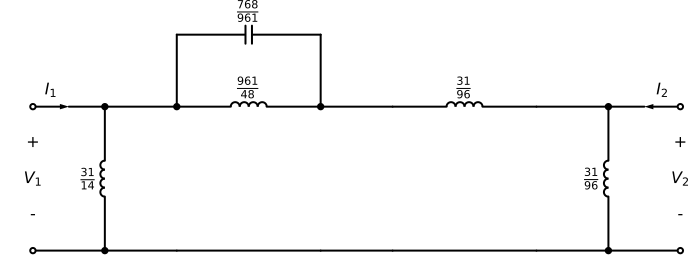

In [15]:
d3 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
d3 = dibujar_elemento_derivacion(d3, 'L', L1_1)
d3 = dibujar_espacio_derivacion(d3)
d3 = dibujar_tanque_serie(d3, L2_1, C_1)
d3 = dibujar_espacio_derivacion(d3)
d3 = dibujar_elemento_serie(d3, 'L', L3A_3)
d3 = dibujar_espacio_derivacion(d3)
d3 = dibujar_elemento_derivacion(d3, 'L', L3B_3)
d3 = dibujar_puerto_salida(
    d3,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2$',
)
display(d3)

#### Circuito de transferencia con excitación Norton

Se incluye la fuente de corriente $I_g$ en paralelo con $R_g=1\,\Omega$ en la entrada y se deja abierto el puerto 2, según el circuito de transferencia de LTspice.

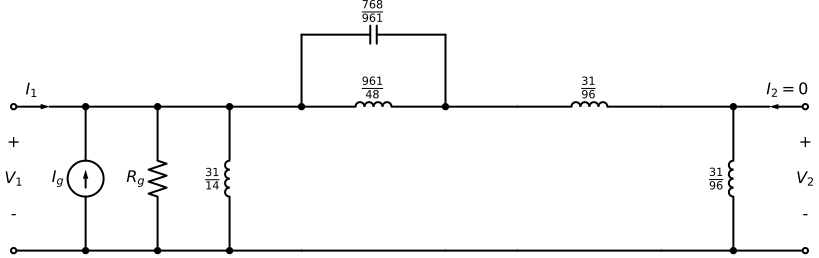

In [16]:
dc3 = dibujar_puerto_entrada(
    Drawing(unit=4),
    voltage_lbl=('+', r'$V_1$', '-'),
    current_lbl=r'$I_1$',
)
dc3 = dibujar_elemento_derivacion(dc3, 'I', r'I_g')
dc3 = dibujar_espacio_derivacion(dc3)
dc3 = dibujar_elemento_derivacion(dc3, 'R', r'R_g')
dc3 = dibujar_espacio_derivacion(dc3)
dc3 = dibujar_elemento_derivacion(dc3, 'L', L1_1)
dc3 = dibujar_espacio_derivacion(dc3)
dc3 = dibujar_tanque_serie(dc3, L2_1, C_1)
dc3 = dibujar_espacio_derivacion(dc3)
dc3 = dibujar_elemento_serie(dc3, 'L', L3A_3)
dc3 = dibujar_espacio_derivacion(dc3)
dc3 = dibujar_elemento_derivacion(dc3, 'L', L3B_3)
dc3 = dibujar_puerto_salida(
    dc3,
    voltage_lbl=('+', r'$V_2$', '-'),
    current_lbl=r'$I_2=0$',
)
display(dc3)

#### Remociones de síntesis y salida con toma intermedia

La función $Z_{11}$ del punto 3 se sintetiza desde el puerto 1 usando $Y_{\mathrm{in},1}^{(I_2=0)}=1/Z_{11}$, la admitancia de entrada con el puerto 2 abierto (no el parámetro matricial $Y_{11}$). La bobina $L_3$ obtenida se divide en dos inductancias iguales; la salida $V_2$ se toma sobre $L_{3B}$, por lo que $Z_{21}$ queda escalado por $1/2$.

In [17]:
Yin1_I2zero_s3 = sp.factor(1 / Z11_3)
Y2_s3, YL1_s3 = remover_polo_dc(Yin1_I2zero_s3, omega_zero=0.25)
Y2_s3 = sp.factor(sp.nsimplify(Y2_s3))
YL1_s3 = sp.factor(sp.nsimplify(YL1_s3))
L1_s3 = sp.simplify(1 / (s * YL1_s3))

print_subtitle("Remoción parcial en continua: extracción de L1")
mostrar_funcion(r"Y_{\mathrm{in},1}^{(I_2=0)}(s)", Yin1_I2zero_s3)
mostrar_funcion("Y_{L_1}(s)", YL1_s3)
mostrar_componente("L_1", L1_s3, "H")
mostrar_funcion("Y_2(s)", Y2_s3)
print("Y2 es FRP:", isFRP(Y2_s3))

assert L1_s3 == L1_1
assert sp.simplify(Y2_s3.subs(s, sp.I/4)) == 0

#### Remoción parcial en continua: extracción de L1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


<IPython.core.display.Math object>

Y2 es FRP: True


In [18]:
Z2_s3 = sp.factor(1 / Y2_s3)
Z4_s3, ZLC_s3, L2_s3, C1_s3 = remover_polo_jw(
    Z2_s3, omega=0.25, isImpedance=True
)
Z4_s3 = sp.factor(sp.nsimplify(Z4_s3, tolerance=1e-10))
ZLC_s3 = sp.factor(sp.nsimplify(ZLC_s3, tolerance=1e-10))
L2_s3 = sp.nsimplify(L2_s3, tolerance=1e-10)
C1_s3 = sp.nsimplify(C1_s3, tolerance=1e-10)
L3_total_s3 = sp.simplify(sp.limit(Z4_s3/s, s, sp.oo))
L3A_synth = sp.simplify(L3_total_s3 / 2)
L3B_synth = sp.simplify(L3_total_s3 / 2)

print_subtitle("Remoción del polo finito y división de L3")
mostrar_funcion("Z_{L_2C_1}(s)", ZLC_s3)
mostrar_componente("L_2", L2_s3, "H")
mostrar_componente("C_1", C1_s3, "F")
mostrar_funcion("Z_4(s)", Z4_s3)
mostrar_componente("L_{3,total}", L3_total_s3, "H")
mostrar_componente("L_{3A}=L_{3B}", L3A_synth, "H")

assert L2_s3 == L2_1 and C1_s3 == C_1
assert L3A_synth == L3A_3 and L3B_synth == L3B_3

#### Remoción del polo finito y división de L3

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: H


<IPython.core.display.Math object>

Unidad: H


#### Transferencia cargada y nivel de la banda pasante

El límite de alta frecuencia de la transferencia normalizada es uno. La toma sobre la mitad de L3 da k=1/2, equivalente a −6.02 dB (aproximadamente −6 dB), como en la resolución manuscrita.

In [19]:
T3 = sp.factor(Z21_3 / (1 + Z11_3))
T3_objetivo_unitario = s * (s**2 + sp.Rational(1, 16)) / (s**3 + 2*s**2 + 2*s + 1)
k3 = sp.simplify(T3 / T3_objetivo_unitario)
db_pasabanda_3 = 20 * sp.log(k3, 10)

print_subtitle("Punto 3: transferencia con excitación Norton")
mostrar_funcion("T_3(s)=V_2/I_g", T3)
mostrar_funcion("T_{objetivo, k=1}(s)", T3_objetivo_unitario)
mostrar_componente("k_3", k3, "adimensional")
mostrar_componente("Ganancia asintótica", sp.limit(T3, s, sp.oo), "V/A")
print_latex(a_equal_b_latex_s("Ganancia_{dB}", sp.N(db_pasabanda_3, 6)))

assert k3 == sp.Rational(1, 2)
assert sp.limit(T3, s, sp.oo) == sp.Rational(1, 2)

#### Punto 3: transferencia con excitación Norton

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Unidad: adimensional


<IPython.core.display.Math object>

Unidad: V/A


<IPython.core.display.Math object>

El código localiza el máximo entre los dos ceros finitos y ajusta el nivel a −6 dB.